In [92]:
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

def generate_mini_dsprites(n_samples=50000, img_size=32, seed=42):
    rng = np.random.default_rng(seed)
    H = W = img_size

    yy, xx = np.mgrid[:H, :W].astype(np.float32)
    xx = xx[None, :, :] + 0.5  
    yy = yy[None, :, :] + 0.5

    scale = rng.uniform(4.0, 9.0, size=n_samples).astype(np.float32)
    r = scale[:, None, None]

    margin = 2.0
    max_r = 9.0
    cx = rng.uniform(margin + max_r, W - margin - max_r, size=n_samples).astype(np.float32)
    cy = rng.uniform(margin + max_r, H - margin - max_r, size=n_samples).astype(np.float32)

    dx = np.abs(xx - cx[:, None, None])
    dy = np.abs(yy - cy[:, None, None])

    shape_types = rng.integers(0, 3, size=n_samples)

    circle  = (dx**2 + dy**2) <= (r**2)
    square  = (dx <= r) & (dy <= r)
    diamond = (dx + dy) <= r

    masks = np.where((shape_types == 0)[:, None, None], circle,
            np.where((shape_types == 1)[:, None, None], square, diamond))

    tensor_data = torch.from_numpy(masks.astype(np.float32)).unsqueeze(1)
    return tensor_data

data = generate_mini_dsprites(n_samples=50000, img_size=32)
print("Shape of generated dataset:", data.shape)

batch_size = 64
train_loader = DataLoader(TensorDataset(data), batch_size=batch_size, shuffle=True)


Shape of generated dataset: torch.Size([50000, 1, 32, 32])


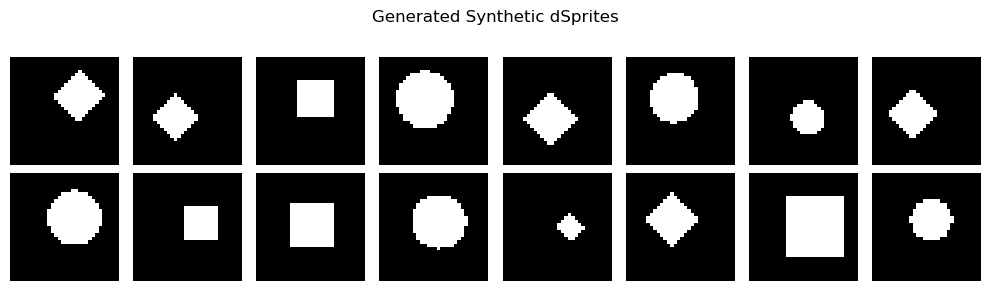

In [93]:
sample_batch = next(iter(train_loader))[0][:16]

fig, axes = plt.subplots(2, 8, figsize=(10, 3))
for idx, ax in enumerate(axes.flat):
    ax.imshow(sample_batch[idx].squeeze(), cmap='gray')
    ax.axis('off')
plt.suptitle("Generated Synthetic dSprites", fontsize=12)
plt.tight_layout()
plt.show()


In [94]:
import torch.nn as nn
import torch.nn.functional as F

class VAE(nn.Module):
    def __init__(self):

        super().__init__()
        
        self.encoder = nn.Sequential(
            nn.Linear(1024 , 400),
            nn.ReLU()
        )

        self.mu = nn.Linear(400,4)
        self.logvar = nn.Linear(400,4)

        self.decoder = nn.Sequential(
            nn.Linear(4 , 400),
            nn.ReLU(),
            nn.Linear(400 , 1024),
        )

    def forward(self , x):

        encoder = self.encoder(x)

        mu = self.mu(encoder)
        logvar = self.logvar(encoder)

        eps = torch.randn_like(logvar)

        std = torch.exp(0.5 * logvar)
            
        z = mu + eps * std

        recon = self.decoder(z)

        return mu , logvar , recon 
    

model = VAE()

In [108]:
def loss_fn(mu , logvar , x , x_recon, beta):

    recon_loss = F.binary_cross_entropy_with_logits(input=x_recon , target=x , reduction='sum')
    
    kl_loss = -0.5 * torch.sum(logvar + 1 - mu ** 2 - torch.exp(logvar))

    return (recon_loss + beta * kl_loss) / x.size(0)

In [96]:
learning_rate = 0.01

optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

In [97]:
def train_loop(dataloader, model, loss_fn, optimizer, beta):
    size = len(dataloader.dataset)
    model.train()
    for batch, X in enumerate(dataloader):
        X = X[0].reshape(-1 , 1024)
        mu , logvar , recon  = model(X)
        loss = loss_fn(mu , logvar , X , recon , beta)


        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        if batch % 100 == 0:
            loss, current = loss.item(), batch * batch_size + len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")


## First case : β = 1 (standard VAE)

In [98]:
for t in range(5):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loop(train_loader, model, loss_fn, optimizer , 1)
print("Done!")

Epoch 1
-------------------------------
loss: 11.131804  [   64/50000]
loss: 0.904873  [ 6464/50000]
loss: 0.870332  [12864/50000]
loss: 0.824108  [19264/50000]
loss: 0.820726  [25664/50000]
loss: 0.721542  [32064/50000]
loss: 0.689685  [38464/50000]
loss: 0.718854  [44864/50000]
Epoch 2
-------------------------------
loss: 0.825866  [   64/50000]
loss: 0.783100  [ 6464/50000]
loss: 0.727769  [12864/50000]
loss: 0.729580  [19264/50000]
loss: 0.703274  [25664/50000]
loss: 0.642612  [32064/50000]
loss: 0.615977  [38464/50000]
loss: 0.660108  [44864/50000]
Epoch 3
-------------------------------
loss: 0.693538  [   64/50000]
loss: 0.680465  [ 6464/50000]
loss: 0.602361  [12864/50000]
loss: 0.621438  [19264/50000]
loss: 0.546090  [25664/50000]
loss: 0.674104  [32064/50000]
loss: 0.595545  [38464/50000]
loss: 0.613218  [44864/50000]
Epoch 4
-------------------------------
loss: 0.603120  [   64/50000]
loss: 0.518987  [ 6464/50000]
loss: 0.558874  [12864/50000]
loss: 0.591603  [19264/50000]

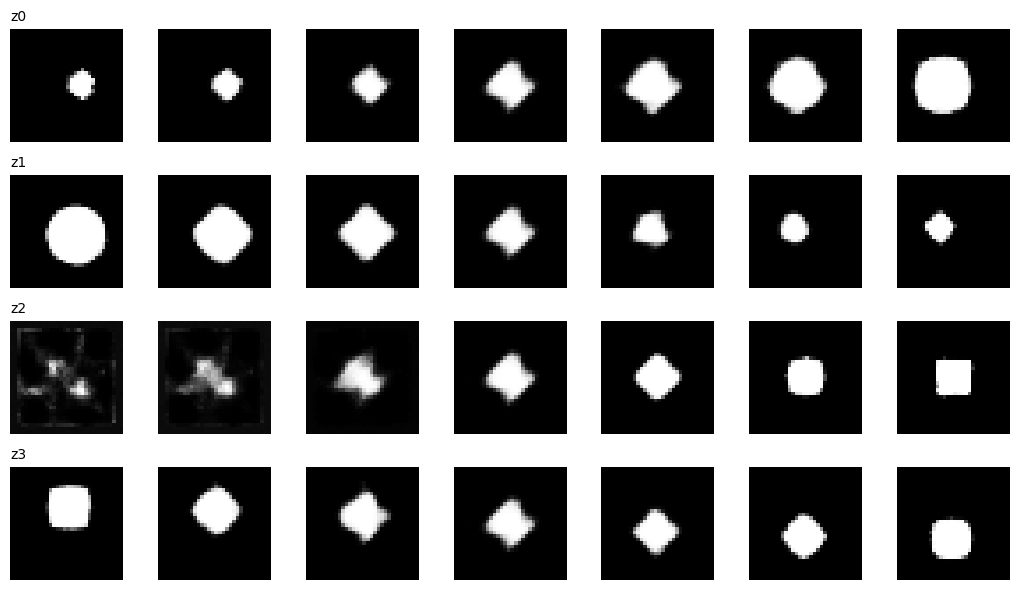

In [99]:
@torch.no_grad()
def plot_latent_traversalsl(latent_dim=4, n_steps=7, val_range=(-2.5, 2.5)):
    model.decoder.eval()
    fig, axes = plt.subplots(latent_dim, n_steps, figsize=(n_steps * 1.5, latent_dim * 1.5))
    values = torch.linspace(val_range[0], val_range[1], n_steps)

    for i in range(latent_dim):
        z = torch.zeros(n_steps, latent_dim)
        z[:, i] = values

        recon_logits = model.decoder(z)
        recon_imgs = torch.sigmoid(recon_logits).view(-1, 32 , 32).numpy()

        for j in range(n_steps):
            ax = axes[i, j] if latent_dim > 1 else axes[j]
            ax.imshow(recon_imgs[j], cmap='gray')
            ax.axis('off')
            if j == 0:
                ax.set_title(f"z{i}", loc='left', fontsize=10)

    plt.tight_layout()
    plt.show()


plot_latent_traversalsl()

## Second case : β = 4

In [100]:
for t in range(5):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loop(train_loader, model, loss_fn, optimizer , 4)
print("Done!")

Epoch 1
-------------------------------
loss: 1.143846  [   64/50000]
loss: 1.113773  [ 6464/50000]
loss: 1.019634  [12864/50000]
loss: 1.039044  [19264/50000]
loss: 1.032822  [25664/50000]
loss: 1.025043  [32064/50000]
loss: 1.006774  [38464/50000]
loss: 1.088307  [44864/50000]
Epoch 2
-------------------------------
loss: 1.090697  [   64/50000]
loss: 1.032615  [ 6464/50000]
loss: 1.015140  [12864/50000]
loss: 1.020232  [19264/50000]
loss: 1.102304  [25664/50000]
loss: 0.981348  [32064/50000]
loss: 0.996812  [38464/50000]
loss: 1.062924  [44864/50000]
Epoch 3
-------------------------------
loss: 1.030276  [   64/50000]
loss: 0.984163  [ 6464/50000]
loss: 1.006566  [12864/50000]
loss: 0.997141  [19264/50000]
loss: 1.015041  [25664/50000]
loss: 0.949337  [32064/50000]
loss: 0.991864  [38464/50000]
loss: 0.978287  [44864/50000]
Epoch 4
-------------------------------
loss: 1.015295  [   64/50000]
loss: 0.994159  [ 6464/50000]
loss: 1.009074  [12864/50000]
loss: 1.053960  [19264/50000]


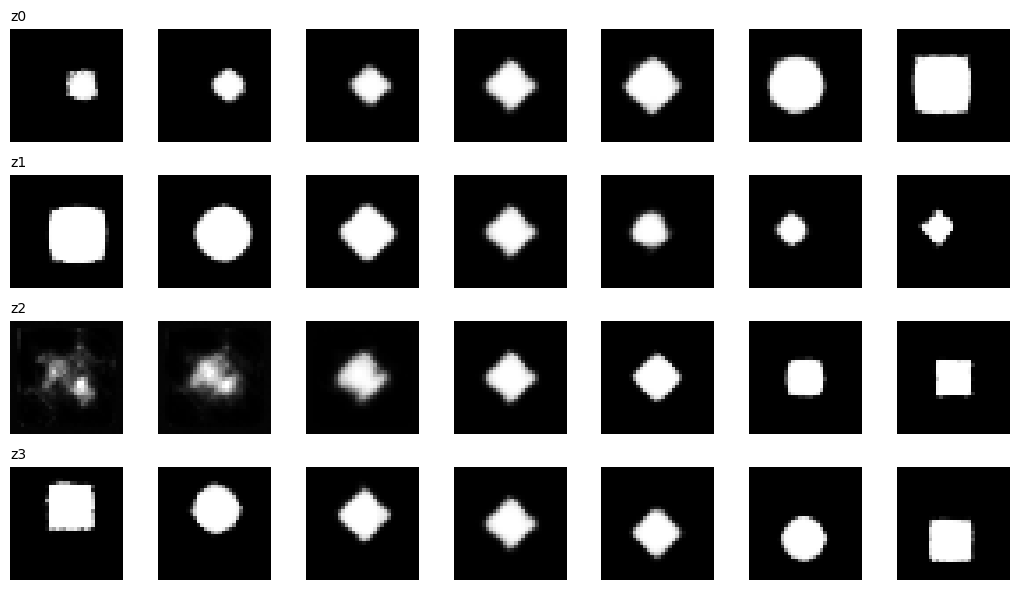

In [101]:
@torch.no_grad()
def plot_latent_traversalsl(latent_dim=4, n_steps=7, val_range=(-2.5, 2.5)):
    model.decoder.eval()
    fig, axes = plt.subplots(latent_dim, n_steps, figsize=(n_steps * 1.5, latent_dim * 1.5))
    values = torch.linspace(val_range[0], val_range[1], n_steps)

    for i in range(latent_dim):
        z = torch.zeros(n_steps, latent_dim)
        z[:, i] = values

        recon_logits = model.decoder(z)
        recon_imgs = torch.sigmoid(recon_logits).view(-1, 32 , 32).numpy()

        for j in range(n_steps):
            ax = axes[i, j] if latent_dim > 1 else axes[j]
            ax.imshow(recon_imgs[j], cmap='gray')
            ax.axis('off')
            if j == 0:
                ax.set_title(f"z{i}", loc='left', fontsize=10)

    plt.tight_layout()
    plt.show()


plot_latent_traversalsl()

## Third case : β = 10

In [104]:
for t in range(100):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loop(train_loader, model, loss_fn, optimizer , 10)
print("Done!")

Epoch 1
-------------------------------
loss: 1.769392  [   64/50000]
loss: 1.692503  [ 6464/50000]
loss: 1.745627  [12864/50000]
loss: 1.781685  [19264/50000]
loss: 1.647225  [25664/50000]
loss: 1.640907  [32064/50000]
loss: 1.768685  [38464/50000]
loss: 1.665787  [44864/50000]
Epoch 2
-------------------------------
loss: 1.658131  [   64/50000]
loss: 1.715335  [ 6464/50000]
loss: 1.656580  [12864/50000]
loss: 1.627354  [19264/50000]
loss: 1.646652  [25664/50000]
loss: 1.594614  [32064/50000]
loss: 1.719386  [38464/50000]
loss: 1.695988  [44864/50000]
Epoch 3
-------------------------------
loss: 1.646683  [   64/50000]
loss: 1.641463  [ 6464/50000]
loss: 1.617391  [12864/50000]
loss: 1.671463  [19264/50000]
loss: 1.611613  [25664/50000]
loss: 1.703055  [32064/50000]
loss: 1.677081  [38464/50000]
loss: 1.591787  [44864/50000]
Epoch 4
-------------------------------
loss: 1.585159  [   64/50000]
loss: 1.699602  [ 6464/50000]
loss: 1.628796  [12864/50000]
loss: 1.712798  [19264/50000]


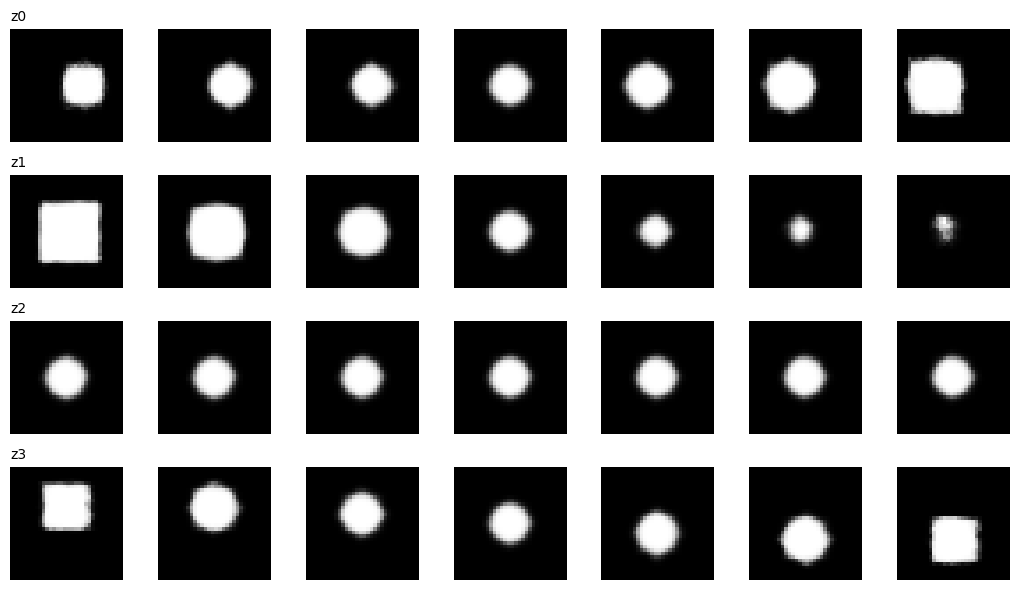

In [106]:
@torch.no_grad()
def plot_latent_traversalsl(latent_dim=4, n_steps=7, val_range=(-2.5, 2.5)):
    model.decoder.eval()
    fig, axes = plt.subplots(latent_dim, n_steps, figsize=(n_steps * 1.5, latent_dim * 1.5))
    values = torch.linspace(val_range[0], val_range[1], n_steps)

    for i in range(latent_dim):
        z = torch.zeros(n_steps, latent_dim)
        z[:, i] = values

        recon_logits = model.decoder(z)
        recon_imgs = torch.sigmoid(recon_logits).view(-1, 32 , 32).numpy()

        for j in range(n_steps):
            ax = axes[i, j] if latent_dim > 1 else axes[j]
            ax.imshow(recon_imgs[j], cmap='gray')
            ax.axis('off')
            if j == 0:
                ax.set_title(f"z{i}", loc='left', fontsize=10)

    plt.tight_layout()
    plt.show()


plot_latent_traversalsl()